# 20 — Local Graph + Temporal Modeling
## Can learned message passing use local spatial dependence better than handcrafted aggregation?

Notebook 19B showed two important points on the locked T2 regional domain:

1. the local `LR13` baseline remained extremely strong overall;
2. generic neighboring activity showed only a small added signal, with the clearest
   indication appearing at a more local spatial scale and in Emerging-3 cases.

Notebook 20 therefore tests the next research question:

> Can a learned graph representation exploit local spatial dependence better than
> handcrafted neighbor aggregation, and does combining graph message passing with
> temporal sequence modeling add information beyond a temporal-only model?

### Models

```text
LR13          local linear benchmark
NodeMLP       nonlinear static control, no graph
GCN           learned spatial message passing, day t only
GAT           learned spatial attention, day t only

NodeGRU       temporal-only control
GCN-GRU       graph + temporal
GAT-GRU       graph-attention + temporal
```

Temporal models are tested with **7-day and 14-day sequences**.

### Primary graph

The primary graph is **Queen-style adjacency defined directly from the 0.25° grid**:
horizontal, vertical, and diagonal retained land cells one grid step apart.

This graph is *not* selected because a certain radius performed best on August. It is
a geometry-defined local neighborhood derived from the spatial representation itself.

### Feature parity

All neural models use the same **13 local fire features** as LR13:

- 3 current-day local fire features;
- 10 lag/rolling local fire-history features.

Weather and handcrafted spatial/wind features are excluded from the primary NB20
comparison so the effect of learned graph message passing is not confounded.

### Evaluation discipline

- region: locked T2 / 133 nodes;
- development only through August;
- May–July: model training;
- last part of July: internal epoch tuning;
- August: development validation;
- September: **SEALED**;
- primary metric: PR-AUC;
- report Overall, Emerging-3, Persistent-context, runtime, and seed stability.

Attention weights are learned associations, not causal explanations of fire spread.

In [2]:
# 1. Imports and run controls

from pathlib import Path
import sys
import json
import importlib
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    brier_score_loss,
)

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 260)

RANDOM_STATE = 42

# Final development run: 3 seeds.
# If you only want to check that the notebook works, set QUICK_MODE=True first.
QUICK_MODE = False

if QUICK_MODE:
    SEEDS = [42]
    MAX_EPOCHS = 50
    PATIENCE = 8
else:
    SEEDS = [42, 52, 62]
    MAX_EPOCHS = 120
    PATIENCE = 15

HIDDEN_DIM = 24
GAT_HEADS = 2
DROPOUT = 0.15
BATCH_SIZE = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

INTERNAL_TUNE_START = pd.Timestamp("2026-07-18")
TRAIN_END = pd.Timestamp("2026-07-31")
VAL_START = pd.Timestamp("2026-08-01")
VAL_END = pd.Timestamp("2026-08-31")

RUN_TEST = False

In [3]:
# 2. Resolve project root and locked-domain metadata

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )
    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional dataset. "
        "Open VS Code at the skripsi-karhut root or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

LOCK_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_dataset"
    / "exports"
    / "regional_domain_lock_train_only.json"
)

METHODOLOGY_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_dataset"
    / "exports"
    / "regional_025_methodology_metadata.json"
)

for p in [
    DATA_PATH,
    LOCK_PATH,
    METHODOLOGY_PATH,
]:
    if not p.exists():
        raise FileNotFoundError(
            f"Required artifact missing: {p}"
        )

lock_metadata = json.loads(
    LOCK_PATH.read_text(encoding="utf-8")
)

methodology_metadata = json.loads(
    METHODOLOGY_PATH.read_text(encoding="utf-8")
)

LOCKED_REGION_ID = str(
    lock_metadata["candidate_id"]
)

EXPECTED_NODES = int(
    methodology_metadata["weather"]["requested_grid_centers"]
)

assert lock_metadata.get("selection_uses_emerging3") is False
assert lock_metadata.get("selection_uses_august") is False
assert lock_metadata.get("selection_uses_september") is False

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_graph_temporal"
    / LOCKED_REGION_ID.lower()
)

EXPORT_DIR = RESULTS_DIR / "exports"
FIGURES_DIR = RESULTS_DIR / "figures"

for p in [
    RESULTS_DIR,
    EXPORT_DIR,
    FIGURES_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("Region       :", LOCKED_REGION_ID)
print("Nodes        :", EXPECTED_NODES)
print("Results      :", RESULTS_DIR)

PROJECT_ROOT : c:\Users\Asus\Documents\skripsi-karhut
Region       : T2
Nodes        : 133
Results      : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2


In [4]:
# 3. Import reusable modules

SRC_ROOT = PROJECT_ROOT / "src"

if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

import karhut.evaluation as evaluation
import karhut.models as graph_models

importlib.reload(evaluation)
importlib.reload(graph_models)

import torch

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)

if DEVICE == "cuda":
    print("GPU     :", torch.cuda.get_device_name(0))
else:
    print(
        "CPU is acceptable for this graph size; "
        "GPU is optional rather than required."
    )

PyTorch : 2.14.0+cpu
Device  : cpu
CPU is acceptable for this graph size; GPU is optional rather than required.


In [5]:
# 4. Load development data only

regional_all = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

regional_all["cell_id"] = regional_all["cell_id"].astype(str)

N_NODES = int(
    regional_all["cell_id"].nunique()
)

assert N_NODES == EXPECTED_NODES
assert regional_all.duplicated(
    ["date", "cell_id"]
).sum() == 0

# Development frame stops at August.
dev = (
    regional_all[
        regional_all["date"] <= VAL_END
    ]
    .copy()
    .sort_values(
        ["date", "cell_id"]
    )
    .reset_index(drop=True)
)

assert dev["date"].max() == VAL_END
assert not (
    dev["date"] >= pd.Timestamp("2026-09-01")
).any()

print("Development rows :", len(dev))
print("Development end  :", dev["date"].max().date())
print("September        : SEALED")

Development rows : 15428
Development end  : 2026-08-31
September        : SEALED


In [6]:
# 5. Primary feature set: exact LR13 local features

CURRENT_DAY_FIRE = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

FIRE_HISTORY = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

FEATURES_13 = (
    CURRENT_DAY_FIRE
    + FIRE_HISTORY
)

TARGET = "target_fire_active_t1"
CONTEXT = "active_days_prev3_incl_t"

required = [
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    TARGET,
    CONTEXT,
    *FEATURES_13,
]

missing = sorted(
    set(required)
    - set(dev.columns)
)

if missing:
    raise ValueError(
        f"Dataset is missing required columns: {missing}"
    )

print("Neural input features:", len(FEATURES_13))
display(pd.DataFrame({"feature": FEATURES_13}))

Neural input features: 13


,feature
0,fire_active
1,fire_count
2,frp_sum
3,fire_count_lag1
4,fire_count_lag3
5,fire_count_lag7
6,frp_sum_lag1
7,frp_sum_lag3
8,frp_sum_lag7
9,fire_count_roll3


# PART A — Geometry-defined local graph

The graph is based on the grid itself, not on validation performance.

For a 0.25° grid, each retained node can connect to up to eight Queen neighbors:
N, NE, E, SE, S, SW, W, NW, if those neighboring land nodes are retained.

In [7]:
# 6. Build Queen-style local graph

node_table = (
    dev[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
        ]
    ]
    .drop_duplicates("cell_id")
    .sort_values("cell_id")
    .reset_index(drop=True)
)

node_ids = (
    node_table["cell_id"]
    .astype(str)
    .tolist()
)

edges = graph_models.build_grid_queen_edges(
    node_table,
    grid_step_deg=0.25,
    tolerance_deg=0.02,
)

audit = graph_models.graph_audit(
    node_ids,
    edges,
)

display(
    pd.DataFrame(
        [audit]
    ).drop(
        columns=["component_sizes"]
    )
)

print(
    "Component sizes:",
    audit["component_sizes"],
)

display(edges.head(12))

,nodes,directed_edges,undirected_edges,degree_min,degree_median,degree_mean,degree_max,isolated_nodes,components,largest_component_nodes
0,133,922,461,3,8.0,6.932331,8,0,1,133


Component sizes: [133]


,source_cell_id,target_cell_id,distance_km
0,regional025_10_23,regional025_10_22,27.783886
1,regional025_11_22,regional025_10_22,27.798770
2,regional025_11_23,regional025_10_22,39.304215
3,regional025_9_22,regional025_10_22,27.798770
4,regional025_9_23,regional025_10_22,39.301409
5,regional025_10_22,regional025_10_23,27.783886
6,regional025_10_24,regional025_10_23,27.783886
7,regional025_11_22,regional025_10_23,39.304215
8,regional025_11_23,regional025_10_23,27.798770
9,regional025_11_24,regional025_10_23,39.304215


In [8]:
# 7. Build dense adjacency matrices

A = graph_models.edges_to_adjacency(
    node_ids,
    edges,
)

A_NORM = graph_models.normalize_adjacency(
    A,
    add_self_loops=True,
)

A_MASK = graph_models.adjacency_mask(
    A,
    add_self_loops=True,
)

assert A.shape == (
    EXPECTED_NODES,
    EXPECTED_NODES,
)

assert np.allclose(
    A,
    A.T,
)

print("Adjacency shape :", A.shape)
print("Raw density     :", round(float(A.mean()), 6))
print("Self loops in model adjacency:", int(np.diag(A_MASK).sum()))

Adjacency shape : (133, 133)
Raw density     : 0.052123
Self loops in model adjacency: 133


# PART B — Daily tensor and sequence construction

Each tensor is aligned as:

```text
date × node × feature
```

Temporal models then create:

```text
sequence × lookback_day × node × feature
```

The label stored on predictor date `t` is the hotspot-detection target for `t+1`.

In [9]:
# 8. Convert panel to daily dense arrays

daily = graph_models.panel_to_daily_arrays(
    dev,
    FEATURES_13,
    TARGET,
    CONTEXT,
    node_ids,
)

dates = daily["dates"]
X_RAW = daily["X"]
Y = daily["y"]
C = daily["context"]

print("Daily X :", X_RAW.shape)
print("Daily y :", Y.shape)
print("Dates   :", pd.Timestamp(dates[0]).date(), "→", pd.Timestamp(dates[-1]).date())

assert X_RAW.shape[1] == EXPECTED_NODES
assert X_RAW.shape[2] == len(FEATURES_13)

Daily X : (116, 133, 13)
Daily y : (116, 133)
Dates   : 2026-05-08 → 2026-08-31


In [10]:
# 9. Dataset helper for one sequence length

def prepare_sequence_data(seq_len):
    # Internal tuning scaler: fit only before the internal July tune period.
    core_date_mask = (
        dates < np.datetime64(INTERNAL_TUNE_START)
    )

    mean_core, std_core = (
        graph_models.fit_standardizer(
            X_RAW,
            core_date_mask,
        )
    )

    X_core_scaled = (
        graph_models.apply_standardizer(
            X_RAW,
            mean_core,
            std_core,
        )
    )

    seq_core = graph_models.make_sequences(
        dates,
        X_core_scaled,
        Y,
        C,
        seq_len=seq_len,
    )

    seq_dates = pd.to_datetime(
        seq_core["dates"]
    )

    core_mask = (
        seq_dates < INTERNAL_TUNE_START
    )
    tune_mask = (
        (seq_dates >= INTERNAL_TUNE_START)
        & (seq_dates <= TRAIN_END)
    )

    # Final scaler for full May-Jul refit.
    full_train_date_mask = (
        dates <= np.datetime64(TRAIN_END)
    )

    mean_full, std_full = (
        graph_models.fit_standardizer(
            X_RAW,
            full_train_date_mask,
        )
    )

    X_full_scaled = (
        graph_models.apply_standardizer(
            X_RAW,
            mean_full,
            std_full,
        )
    )

    seq_full = graph_models.make_sequences(
        dates,
        X_full_scaled,
        Y,
        C,
        seq_len=seq_len,
    )

    full_dates = pd.to_datetime(
        seq_full["dates"]
    )

    train_mask = (
        full_dates <= TRAIN_END
    )
    val_mask = (
        (full_dates >= VAL_START)
        & (full_dates <= VAL_END)
    )

    return {
        "seq_len": seq_len,
        "core": {
            "X": seq_core["X"][core_mask],
            "y": seq_core["y"][core_mask],
        },
        "tune": {
            "X": seq_core["X"][tune_mask],
            "y": seq_core["y"][tune_mask],
        },
        "train": {
            "X": seq_full["X"][train_mask],
            "y": seq_full["y"][train_mask],
            "dates": full_dates[train_mask],
        },
        "val": {
            "X": seq_full["X"][val_mask],
            "y": seq_full["y"][val_mask],
            "context": seq_full["context"][val_mask],
            "dates": full_dates[val_mask],
        },
    }


prepared = {
    1: prepare_sequence_data(1),
    7: prepare_sequence_data(7),
    14: prepare_sequence_data(14),
}

for seq_len, pack in prepared.items():
    print(
        f"L={seq_len:>2} | "
        f"core={len(pack['core']['X']):>2} dates | "
        f"tune={len(pack['tune']['X']):>2} | "
        f"full train={len(pack['train']['X']):>2} | "
        f"August={len(pack['val']['X']):>2}"
    )

L= 1 | core=71 dates | tune=14 | full train=85 | August=31
L= 7 | core=65 dates | tune=14 | full train=79 | August=31
L=14 | core=58 dates | tune=14 | full train=72 | August=31


## Why internal July tuning?

August is the development validation set used to compare architectures.

To avoid using August repeatedly for neural early stopping, NB20 selects the number of
training epochs using only the last part of July. The selected epoch count is then
refit from scratch on all May–July data before August evaluation.

In [11]:
# 10. LR13 reference on the same August population

lr_train = (
    dev[
        dev["date"] <= TRAIN_END
    ]
    .copy()
)

lr_val = (
    dev[
        dev["date"].between(
            VAL_START,
            VAL_END,
            inclusive="both",
        )
    ]
    .copy()
)

lr13 = evaluation.fit_logistic(
    lr_train,
    FEATURES_13,
    TARGET,
    random_state=RANDOM_STATE,
)

lr_score = lr13.predict_proba(
    lr_val[FEATURES_13]
)[:, 1]

lr_metrics = evaluation.binary_metrics(
    lr_val[TARGET],
    lr_score,
    threshold=0.5,
)

print("LR13 August reference")
display(pd.DataFrame([lr_metrics]))

LR13 August reference


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,0.877455,0.858476,0.707635,0.87598,0.782859,0.744361,0.196675,0.5


# PART C — Neural architecture run

Static controls:

- `NodeMLP`: nonlinearity without graph;
- `GCN`: graph convolution;
- `GAT`: graph attention.

Temporal controls:

- `NodeGRU`: sequence modeling without graph;
- `GCN-GRU`: graph representation at each day followed by GRU;
- `GAT-GRU`: graph attention at each day followed by GRU.

For every neural configuration and seed:

1. train on early May–July;
2. select epoch using internal late-July PR-AUC;
3. reinitialize;
4. refit all May–July for that epoch count;
5. evaluate August once.

In [12]:
# 11. Configuration table

CONFIGS = [
    {
        "name": "NodeMLP",
        "kind": "mlp",
        "seq_len": 1,
    },
    {
        "name": "GCN",
        "kind": "gcn",
        "seq_len": 1,
    },
    {
        "name": "GAT",
        "kind": "gat",
        "seq_len": 1,
    },
    {
        "name": "NodeGRU-L7",
        "kind": "nodegru",
        "seq_len": 7,
    },
    {
        "name": "GCN-GRU-L7",
        "kind": "gcngru",
        "seq_len": 7,
    },
    {
        "name": "GAT-GRU-L7",
        "kind": "gatgru",
        "seq_len": 7,
    },
    {
        "name": "NodeGRU-L14",
        "kind": "nodegru",
        "seq_len": 14,
    },
    {
        "name": "GCN-GRU-L14",
        "kind": "gcngru",
        "seq_len": 14,
    },
    {
        "name": "GAT-GRU-L14",
        "kind": "gatgru",
        "seq_len": 14,
    },
]

display(pd.DataFrame(CONFIGS))
print("Seeds:", SEEDS)
print("Quick mode:", QUICK_MODE)

,name,kind,seq_len
0,NodeMLP,mlp,1
1,GCN,gcn,1
2,GAT,gat,1
3,NodeGRU-L7,nodegru,7
4,GCN-GRU-L7,gcngru,7
5,GAT-GRU-L7,gatgru,7
6,NodeGRU-L14,nodegru,14
7,GCN-GRU-L14,gcngru,14
8,GAT-GRU-L14,gatgru,14


Seeds: [42, 52, 62]
Quick mode: False


In [13]:
# 12. Metric helpers

def flat_metrics(y_true, score, threshold=0.5):
    y = np.asarray(y_true).reshape(-1).astype(int)
    s = np.asarray(score).reshape(-1).astype(float)
    pred = (s >= threshold).astype(int)

    return {
        "PR-AUC": average_precision_score(y, s),
        "ROC-AUC": (
            roc_auc_score(y, s)
            if len(np.unique(y)) > 1
            else np.nan
        ),
        "Precision": precision_score(
            y,
            pred,
            zero_division=0,
        ),
        "Recall": recall_score(
            y,
            pred,
            zero_division=0,
        ),
        "F1": f1_score(
            y,
            pred,
            zero_division=0,
        ),
        "Accuracy": accuracy_score(
            y,
            pred,
        ),
        "Brier": brier_score_loss(
            y,
            s,
        ),
    }


def subgroup_pr(y, score, context):
    y = np.asarray(y)
    score = np.asarray(score)
    context = np.asarray(context)

    emerg_mask = (
        context == 0
    )

    persistent_mask = (
        context > 0
    )

    out = {}

    for label, mask in [
        ("Emerging-3", emerg_mask),
        ("Persistent", persistent_mask),
    ]:
        yy = y[mask].astype(int)
        ss = score[mask]

        out[f"{label} rows"] = int(
            len(yy)
        )
        out[f"{label} positives"] = int(
            yy.sum()
        )
        out[f"{label} PR-AUC"] = (
            average_precision_score(
                yy,
                ss,
            )
            if yy.sum() > 0
            else np.nan
        )

    return out

In [14]:
# 13. Run multi-seed neural experiments

seed_rows = []
prediction_rows = []
epoch_rows = []

for config in CONFIGS:

    name = config["name"]
    kind = config["kind"]
    seq_len = config["seq_len"]

    pack = prepared[seq_len]

    print()
    print("=" * 80)
    print(name, "| sequence length =", seq_len)
    print("=" * 80)

    for seed in SEEDS:

        # Stage A: internal chronological epoch tuning.
        # Seed BEFORE model construction so initialization is reproducible.
        graph_models.set_seed(seed)
        model_tune = graph_models.make_model(
            kind,
            len(FEATURES_13),
            adj_norm=A_NORM,
            adj_mask=A_MASK,
            hidden_dim=HIDDEN_DIM,
            heads=GAT_HEADS,
            dropout=DROPOUT,
        )

        tuned_model, tune_result = (
            graph_models.tune_epochs(
                model_tune,
                pack["core"]["X"],
                pack["core"]["y"],
                pack["tune"]["X"],
                pack["tune"]["y"],
                seed=seed,
                device=DEVICE,
                max_epochs=MAX_EPOCHS,
                patience=PATIENCE,
                batch_size=BATCH_SIZE,
                lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY,
            )
        )

        # Stage B: refit from scratch on all May-Jul.
        # Reinitialize deterministically with the same seed.
        graph_models.set_seed(seed)
        model_final = graph_models.make_model(
            kind,
            len(FEATURES_13),
            adj_norm=A_NORM,
            adj_mask=A_MASK,
            hidden_dim=HIDDEN_DIM,
            heads=GAT_HEADS,
            dropout=DROPOUT,
        )

        model_final, refit_seconds = (
            graph_models.fit_fixed_epochs(
                model_final,
                pack["train"]["X"],
                pack["train"]["y"],
                seed=seed,
                epochs=tune_result.best_epoch,
                device=DEVICE,
                batch_size=BATCH_SIZE,
                lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY,
            )
        )

        val_score = graph_models.predict_proba(
            model_final,
            pack["val"]["X"],
            device=DEVICE,
            batch_size=BATCH_SIZE,
        )

        metrics = flat_metrics(
            pack["val"]["y"],
            val_score,
        )

        sub = subgroup_pr(
            pack["val"]["y"],
            val_score,
            pack["val"]["context"],
        )

        total_seconds = (
            tune_result.seconds
            + refit_seconds
        )

        seed_rows.append({
            "Model": name,
            "Kind": kind,
            "Sequence Length": seq_len,
            "Seed": seed,
            "Best internal epoch": tune_result.best_epoch,
            "Internal tune PR-AUC": tune_result.best_pr_auc,
            "Tune seconds": tune_result.seconds,
            "Refit seconds": refit_seconds,
            "Total seconds": total_seconds,
            **metrics,
            **sub,
        })

        epoch_rows.append({
            "Model": name,
            "Seed": seed,
            "Sequence Length": seq_len,
            "Best internal epoch": tune_result.best_epoch,
            "Internal tune PR-AUC": tune_result.best_pr_auc,
        })

        # Save node-date August predictions for later diagnostics.
        val_dates = pack["val"]["dates"]
        val_y = pack["val"]["y"]
        val_c = pack["val"]["context"]

        for d_idx, date in enumerate(val_dates):
            for n_idx, node_id in enumerate(node_ids):
                prediction_rows.append({
                    "Model": name,
                    "Seed": seed,
                    "Sequence Length": seq_len,
                    "date": pd.Timestamp(date),
                    "cell_id": node_id,
                    "y_true": int(val_y[d_idx, n_idx]),
                    "score": float(val_score[d_idx, n_idx]),
                    "active_days_prev3_incl_t": float(val_c[d_idx, n_idx]),
                })

        print(
            f"seed={seed} | "
            f"epoch={tune_result.best_epoch:>3} | "
            f"Aug PR={metrics['PR-AUC']:.6f} | "
            f"Emerging PR={sub['Emerging-3 PR-AUC']:.6f} | "
            f"{total_seconds:.2f}s"
        )

seed_results = pd.DataFrame(seed_rows)
predictions = pd.DataFrame(prediction_rows)
epoch_diagnostics = pd.DataFrame(epoch_rows)

print()
print("✅ Neural experiment loop complete.")


NodeMLP | sequence length = 1
seed=42 | epoch= 35 | Aug PR=0.878539 | Emerging PR=0.279338 | 1.85s
seed=52 | epoch= 33 | Aug PR=0.878758 | Emerging PR=0.280769 | 1.68s
seed=62 | epoch= 38 | Aug PR=0.878861 | Emerging PR=0.282954 | 1.97s

GCN | sequence length = 1
seed=42 | epoch= 22 | Aug PR=0.766483 | Emerging PR=0.216279 | 2.05s
seed=52 | epoch= 18 | Aug PR=0.785738 | Emerging PR=0.211761 | 1.72s
seed=62 | epoch= 17 | Aug PR=0.783943 | Emerging PR=0.214366 | 1.65s

GAT | sequence length = 1
seed=42 | epoch= 71 | Aug PR=0.823591 | Emerging PR=0.310795 | 19.66s
seed=52 | epoch= 47 | Aug PR=0.825988 | Emerging PR=0.305355 | 13.43s
seed=62 | epoch=112 | Aug PR=0.823626 | Emerging PR=0.306051 | 29.16s

NodeGRU-L7 | sequence length = 7
seed=42 | epoch= 66 | Aug PR=0.867878 | Emerging PR=0.303581 | 27.47s
seed=52 | epoch= 25 | Aug PR=0.864774 | Emerging PR=0.302659 | 11.88s
seed=62 | epoch= 23 | Aug PR=0.865989 | Emerging PR=0.319976 | 11.02s

GCN-GRU-L7 | sequence length = 7
seed=42 | epo

In [15]:
# 14. Seed-level results

display(
    seed_results[
        [
            "Model",
            "Sequence Length",
            "Seed",
            "Best internal epoch",
            "PR-AUC",
            "ROC-AUC",
            "F1",
            "Brier",
            "Emerging-3 PR-AUC",
            "Persistent PR-AUC",
            "Total seconds",
        ]
    ].sort_values(
        [
            "Model",
            "Seed",
        ]
    )
)

,Model,Sequence Length,Seed,Best internal epoch,PR-AUC,ROC-AUC,F1,Brier,Emerging-3 PR-AUC,Persistent PR-AUC,Total seconds
6,GAT,1,42,71,0.823591,0.804519,0.708340,0.328021,0.310795,0.858285,19.664092
7,GAT,1,52,47,0.825988,0.804588,0.709525,0.321083,0.305355,0.861287,13.434608
8,GAT,1,62,112,0.823626,0.803723,0.711239,0.324672,0.306051,0.857550,29.158047
24,GAT-GRU-L14,14,42,23,0.706794,0.723851,0.712766,0.307880,0.305540,0.743324,83.090753
25,GAT-GRU-L14,14,52,11,0.719723,0.724454,0.698000,0.316982,0.266793,0.780910,51.041994
26,GAT-GRU-L14,14,62,6,0.621190,0.670548,0.700066,0.298976,0.196207,0.744716,35.729170
15,GAT-GRU-L7,7,42,29,0.736930,0.746763,0.710364,0.314221,0.324184,0.767371,55.477703
16,GAT-GRU-L7,7,52,10,0.686962,0.695485,0.697364,0.320332,0.258895,0.755607,25.975901
17,GAT-GRU-L7,7,62,4,0.613584,0.654223,0.698350,0.296454,0.205854,0.728552,16.947068
3,GCN,1,42,22,0.766483,0.742231,0.692370,0.351124,0.216279,0.858993,2.046336


In [16]:
# 15. Mean ± std architecture summary

summary_rows = []

for model_name, group in seed_results.groupby("Model"):

    row = {
        "Model": model_name,
        "Sequence Length": int(
            group["Sequence Length"].iloc[0]
        ),
        "Seeds": int(len(group)),
        "PR-AUC mean": group["PR-AUC"].mean(),
        "PR-AUC std": group["PR-AUC"].std(ddof=0),
        "Emerging PR-AUC mean": group["Emerging-3 PR-AUC"].mean(),
        "Emerging PR-AUC std": group["Emerging-3 PR-AUC"].std(ddof=0),
        "Persistent PR-AUC mean": group["Persistent PR-AUC"].mean(),
        "Persistent PR-AUC std": group["Persistent PR-AUC"].std(ddof=0),
        "Brier mean": group["Brier"].mean(),
        "Total seconds mean": group["Total seconds"].mean(),
        "Best epoch mean": group["Best internal epoch"].mean(),
    }

    summary_rows.append(row)

neural_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(
        "PR-AUC mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

lr_emerging_mask = (
    lr_val[CONTEXT].eq(0)
    .to_numpy()
)

lr_persistent_mask = (
    lr_val[CONTEXT].gt(0)
    .to_numpy()
)

lr_emerging_pr = average_precision_score(
    lr_val.loc[
        lr_emerging_mask,
        TARGET,
    ],
    lr_score[lr_emerging_mask],
)

lr_persistent_pr = average_precision_score(
    lr_val.loc[
        lr_persistent_mask,
        TARGET,
    ],
    lr_score[lr_persistent_mask],
)

lr_reference_row = pd.DataFrame([{
    "Model": "LR13 reference",
    "Sequence Length": 1,
    "Seeds": 1,
    "PR-AUC mean": lr_metrics["PR-AUC"],
    "PR-AUC std": 0.0,
    "Emerging PR-AUC mean": lr_emerging_pr,
    "Emerging PR-AUC std": 0.0,
    "Persistent PR-AUC mean": lr_persistent_pr,
    "Persistent PR-AUC std": 0.0,
    "Brier mean": lr_metrics["Brier"],
    "Total seconds mean": np.nan,
    "Best epoch mean": np.nan,
}])

comparison_summary = (
    pd.concat(
        [
            lr_reference_row,
            neural_summary,
        ],
        ignore_index=True,
    )
    .sort_values(
        "PR-AUC mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(comparison_summary)

,Model,Sequence Length,Seeds,PR-AUC mean,PR-AUC std,Emerging PR-AUC mean,Emerging PR-AUC std,Persistent PR-AUC mean,Persistent PR-AUC std,Brier mean,Total seconds mean,Best epoch mean
0,NodeMLP,1,3,0.878719,0.000134,0.281021,0.001487,0.910223,0.000102,0.201768,1.831706,35.333333
1,LR13 reference,1,1,0.877455,0.000000,0.277072,0.000000,0.909001,0.000000,0.196675,NaN,NaN
2,NodeGRU-L7,7,3,0.866214,0.001277,0.308739,0.007955,0.894325,0.001420,0.224865,16.789192,38.000000
3,NodeGRU-L14,14,3,0.864534,0.002475,0.333609,0.009817,0.891424,0.002685,0.229225,17.438619,20.333333
4,GAT,1,3,0.824401,0.001122,0.307400,0.002417,0.859040,0.001617,0.324592,20.752249,76.666667
5,GCN,1,3,0.778721,0.008685,0.214135,0.001851,0.865326,0.004506,0.353179,1.804698,19.000000
6,GCN-GRU-L14,14,3,0.751623,0.010328,0.227802,0.001995,0.833351,0.010151,0.316611,17.600953,17.333333
7,GCN-GRU-L7,7,3,0.742554,0.025628,0.228199,0.003537,0.824191,0.025949,0.322359,9.838497,16.666667
8,GAT-GRU-L14,14,3,0.682569,0.043721,0.256180,0.045261,0.756317,0.017399,0.307946,56.620639,13.333333
9,GAT-GRU-L7,7,3,0.679159,0.050657,0.262978,0.048394,0.750510,0.016253,0.310336,32.800224,14.333333


# PART D — Clean graph-vs-control comparisons

The interpretation should be **paired by representation**:

Static:
```text
NodeMLP vs GCN vs GAT
```

Temporal:
```text
NodeGRU-L7  vs GCN-GRU-L7  vs GAT-GRU-L7
NodeGRU-L14 vs GCN-GRU-L14 vs GAT-GRU-L14
```

This is more informative than simply asking whether any GNN beats LR13.

In [17]:
# 16. Graph contribution deltas against matched non-graph controls

lookup = (
    neural_summary
    .set_index("Model")
)

delta_rows = []

for graph_model, control in [
    ("GCN", "NodeMLP"),
    ("GAT", "NodeMLP"),
    ("GCN-GRU-L7", "NodeGRU-L7"),
    ("GAT-GRU-L7", "NodeGRU-L7"),
    ("GCN-GRU-L14", "NodeGRU-L14"),
    ("GAT-GRU-L14", "NodeGRU-L14"),
]:
    delta_rows.append({
        "Graph model": graph_model,
        "Matched control": control,
        "Delta overall PR-AUC": (
            lookup.loc[graph_model, "PR-AUC mean"]
            - lookup.loc[control, "PR-AUC mean"]
        ),
        "Delta Emerging PR-AUC": (
            lookup.loc[graph_model, "Emerging PR-AUC mean"]
            - lookup.loc[control, "Emerging PR-AUC mean"]
        ),
        "Delta Persistent PR-AUC": (
            lookup.loc[graph_model, "Persistent PR-AUC mean"]
            - lookup.loc[control, "Persistent PR-AUC mean"]
        ),
    })

graph_deltas = pd.DataFrame(
    delta_rows
)

display(graph_deltas)

,Graph model,Matched control,Delta overall PR-AUC,Delta Emerging PR-AUC,Delta Persistent PR-AUC
0,GCN,NodeMLP,-0.099998,-0.066885,-0.044897
1,GAT,NodeMLP,-0.054318,0.026380,-0.051183
2,GCN-GRU-L7,NodeGRU-L7,-0.123659,-0.080540,-0.070134
3,GAT-GRU-L7,NodeGRU-L7,-0.187055,-0.045761,-0.143815
4,GCN-GRU-L14,NodeGRU-L14,-0.112912,-0.105807,-0.058073
5,GAT-GRU-L14,NodeGRU-L14,-0.181965,-0.077429,-0.135107


In [18]:
# 17. Temporal contribution: L7 vs L14 and LR13 reference

temporal_rows = []

for temporal_model in [
    "NodeGRU-L7",
    "NodeGRU-L14",
    "GCN-GRU-L7",
    "GCN-GRU-L14",
    "GAT-GRU-L7",
    "GAT-GRU-L14",
]:

    temporal_rows.append({
        "Model": temporal_model,
        "Delta overall vs LR13": (
            lookup.loc[temporal_model, "PR-AUC mean"]
            - lr_metrics["PR-AUC"]
        ),
        "Delta Emerging vs LR13": (
            lookup.loc[temporal_model, "Emerging PR-AUC mean"]
            - lr_emerging_pr
        ),
    })

temporal_vs_lr = pd.DataFrame(
    temporal_rows
)

display(temporal_vs_lr)

,Model,Delta overall vs LR13,Delta Emerging vs LR13
0,NodeGRU-L7,-0.011241,0.031666
1,NodeGRU-L14,-0.012920,0.056537
2,GCN-GRU-L7,-0.134900,-0.048874
3,GCN-GRU-L14,-0.125832,-0.049270
4,GAT-GRU-L7,-0.198296,-0.014095
5,GAT-GRU-L14,-0.194886,-0.020892


# PART E — Runtime and stability

These diagnostics address the practical question of whether a larger GPU is needed.

For only 133 nodes, dense GCN/GAT operations are still small. A GPU can speed up
repeated neural experiments, especially GAT-GRU, but this notebook explicitly records
actual runtime so the thesis can report computational cost rather than assume it.

In [19]:
# 18. Runtime summary

runtime_summary = (
    seed_results
    .groupby(
        "Model",
        as_index=False,
    )
    .agg(
        mean_seconds=("Total seconds", "mean"),
        max_seconds=("Total seconds", "max"),
        mean_best_epoch=("Best internal epoch", "mean"),
    )
    .sort_values(
        "mean_seconds"
    )
)

display(runtime_summary)

,Model,mean_seconds,max_seconds,mean_best_epoch
3,GCN,1.804698,2.046336,19.000000
8,NodeMLP,1.831706,1.968133,35.333333
5,GCN-GRU-L7,9.838497,14.276010,16.666667
7,NodeGRU-L7,16.789192,27.466063,38.000000
6,NodeGRU-L14,17.438619,18.515284,20.333333
4,GCN-GRU-L14,17.600953,23.232618,17.333333
0,GAT,20.752249,29.158047,76.666667
2,GAT-GRU-L7,32.800224,55.477703,14.333333
1,GAT-GRU-L14,56.620639,83.090753,13.333333


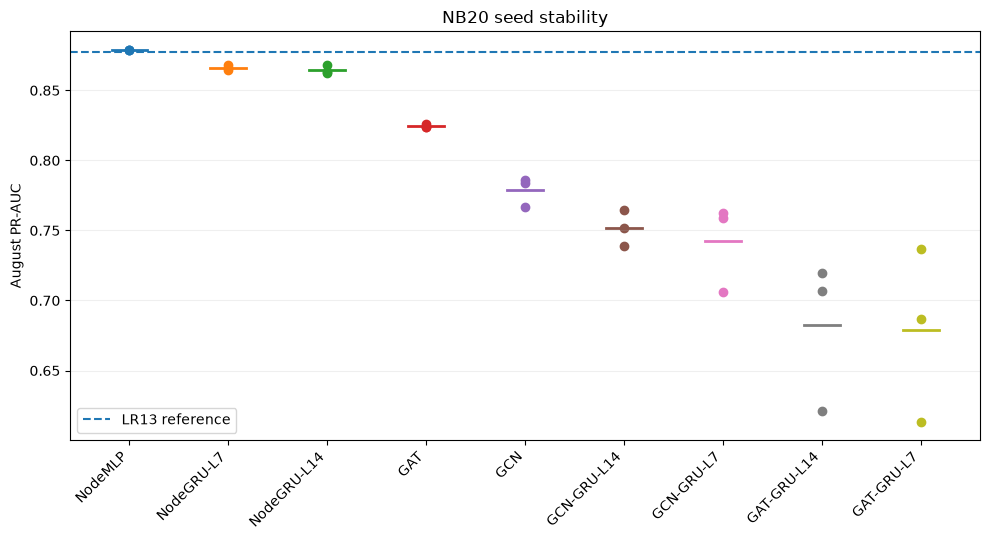

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\figures\01_seed_stability.png


In [20]:
# 19. Seed stability plot

plot_df = (
    seed_results[
        [
            "Model",
            "Seed",
            "PR-AUC",
        ]
    ]
    .copy()
)

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

models_order = (
    neural_summary[
        "Model"
    ].tolist()
)

for i, model_name in enumerate(models_order):
    vals = (
        plot_df[
            plot_df["Model"].eq(model_name)
        ]["PR-AUC"]
        .to_numpy()
    )

    ax.scatter(
        np.full(
            len(vals),
            i,
        ),
        vals,
    )

    ax.plot(
        [
            i - 0.18,
            i + 0.18,
        ],
        [
            vals.mean(),
            vals.mean(),
        ],
        linewidth=2,
    )

ax.axhline(
    lr_metrics["PR-AUC"],
    linestyle="--",
    label="LR13 reference",
)

ax.set_xticks(
    range(len(models_order))
)

ax.set_xticklabels(
    models_order,
    rotation=45,
    ha="right",
)

ax.set_ylabel("August PR-AUC")
ax.set_title("NB20 seed stability")
ax.grid(
    axis="y",
    alpha=0.2,
)
ax.legend()

plt.tight_layout()

stability_fig = (
    FIGURES_DIR
    / "01_seed_stability.png"
)

plt.savefig(
    stability_fig,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Saved:", stability_fig)

# PART F — Daily August diagnostic

This does not replace overall PR-AUC. It helps reveal whether one model's apparent
advantage is concentrated in only a few days.

In [21]:
# 20. Daily PR-AUC for ensemble-mean predictions

ensemble_predictions = (
    predictions
    .groupby(
        [
            "Model",
            "Sequence Length",
            "date",
            "cell_id",
        ],
        as_index=False,
    )
    .agg(
        y_true=("y_true", "first"),
        score=("score", "mean"),
        active_days_prev3_incl_t=("active_days_prev3_incl_t", "first"),
    )
)

daily_rows = []

for (
    model_name,
    date,
), group in ensemble_predictions.groupby(
    [
        "Model",
        "date",
    ]
):
    y = group["y_true"].to_numpy()

    if (
        y.sum() == 0
        or y.sum() == len(y)
    ):
        pr = np.nan
    else:
        pr = average_precision_score(
            y,
            group["score"],
        )

    daily_rows.append({
        "Model": model_name,
        "date": date,
        "Daily PR-AUC": pr,
        "Positive rate": y.mean(),
    })

daily_pr = pd.DataFrame(
    daily_rows
)

display(
    daily_pr
    .groupby(
        "Model",
        as_index=False,
    )
    .agg(
        mean_daily_pr=("Daily PR-AUC", "mean"),
        median_daily_pr=("Daily PR-AUC", "median"),
        valid_days=("Daily PR-AUC", "count"),
    )
    .sort_values(
        "mean_daily_pr",
        ascending=False,
    )
)

,Model,mean_daily_pr,median_daily_pr,valid_days
8,NodeMLP,0.868573,0.879345,30
7,NodeGRU-L7,0.860155,0.875014,30
6,NodeGRU-L14,0.859538,0.874087,30
0,GAT,0.802462,0.840740,30
3,GCN,0.761140,0.771328,30
5,GCN-GRU-L7,0.737370,0.738773,30
4,GCN-GRU-L14,0.734954,0.743333,30
1,GAT-GRU-L14,0.721757,0.728610,30
2,GAT-GRU-L7,0.713129,0.721374,30


# PART G — Save artifacts

No September predictions are created in Notebook 20.

In [22]:
# 21. Save result tables and graph

paths = {
    "seed_results": EXPORT_DIR / "seed_results.csv",
    "summary": EXPORT_DIR / "comparison_summary.csv",
    "graph_deltas": EXPORT_DIR / "graph_control_deltas.csv",
    "temporal_vs_lr": EXPORT_DIR / "temporal_vs_lr13.csv",
    "runtime": EXPORT_DIR / "runtime_summary.csv",
    "predictions": EXPORT_DIR / "august_predictions.csv",
    "daily_pr": EXPORT_DIR / "daily_pr_auc.csv",
    "epochs": EXPORT_DIR / "epoch_diagnostics.csv",
    "edges": EXPORT_DIR / "queen_grid_edges.csv",
}

seed_results.to_csv(
    paths["seed_results"],
    index=False,
)

comparison_summary.to_csv(
    paths["summary"],
    index=False,
)

graph_deltas.to_csv(
    paths["graph_deltas"],
    index=False,
)

temporal_vs_lr.to_csv(
    paths["temporal_vs_lr"],
    index=False,
)

runtime_summary.to_csv(
    paths["runtime"],
    index=False,
)

predictions.to_csv(
    paths["predictions"],
    index=False,
)

daily_pr.to_csv(
    paths["daily_pr"],
    index=False,
)

epoch_diagnostics.to_csv(
    paths["epochs"],
    index=False,
)

edges.to_csv(
    paths["edges"],
    index=False,
)

print("Saved:")
for p in paths.values():
    print("-", p)

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\seed_results.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\comparison_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\graph_control_deltas.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\temporal_vs_lr13.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\runtime_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\august_predictions.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\daily_pr_auc.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\epoch_diagnostics.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph

In [23]:
# 22. Methodology metadata

metadata = {
    "notebook": "20_graph_temporal_local_adjacency",
    "region_id": LOCKED_REGION_ID,
    "nodes": int(EXPECTED_NODES),
    "graph": {
        "type": "Queen-style local grid adjacency",
        "grid_step_deg": 0.25,
        "selection_uses_august_score": False,
        "directed_edges": int(len(edges)),
        "audit": audit,
    },
    "features": FEATURES_13,
    "target": TARGET,
    "timing": "sequence ending at predictor day t -> target t+1",
    "internal_tune_start": str(INTERNAL_TUNE_START.date()),
    "train_end": str(TRAIN_END.date()),
    "validation": [
        str(VAL_START.date()),
        str(VAL_END.date()),
    ],
    "seeds": SEEDS,
    "quick_mode": QUICK_MODE,
    "device": DEVICE,
    "september_evaluated": False,
    "interpretation_guardrail": (
        "GAT attention is associative and not causal evidence of fire spread."
    ),
}

metadata_path = (
    EXPORT_DIR
    / "nb20_methodology_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved:", metadata_path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports\nb20_methodology_metadata.json


In [24]:
# 23. Final automatic summary

print("=== Notebook 20 — Local Graph + Temporal Modeling ===")
print()

print("DOMAIN / GRAPH")
print("Region                  :", LOCKED_REGION_ID)
print("Nodes                   :", EXPECTED_NODES)
print("Adjacency               : Queen-style 0.25° grid")
print("Directed edges          :", len(edges))
print("Mean degree             :", round(audit["degree_mean"], 3))
print("Components              :", audit["components"])
print("Largest component nodes :", audit["largest_component_nodes"])
print("Device                  :", DEVICE)
print("September               : SEALED")
print()

print("OVERALL COMPARISON")
display(comparison_summary)

print("GRAPH VS MATCHED NON-GRAPH CONTROL")
display(graph_deltas)

print("TEMPORAL MODELS VS LR13")
display(temporal_vs_lr)

print("RUNTIME")
display(runtime_summary)

best_overall_neural = neural_summary.iloc[0]
best_emerging_neural = (
    neural_summary
    .sort_values(
        "Emerging PR-AUC mean",
        ascending=False,
    )
    .iloc[0]
)

print()
print(
    "Highest neural mean overall PR-AUC:",
    best_overall_neural["Model"],
    "→",
    round(
        float(
            best_overall_neural["PR-AUC mean"]
        ),
        6,
    ),
)

print(
    "Highest neural mean Emerging PR-AUC:",
    best_emerging_neural["Model"],
    "→",
    round(
        float(
            best_emerging_neural["Emerging PR-AUC mean"]
        ),
        6,
    ),
)

print()
print(
    "Interpretation rule: do not conclude that graph is useful merely because "
    "a GNN beats LR13. Compare GCN/GAT against NodeMLP and GCN-GRU/GAT-GRU "
    "against the sequence-matched NodeGRU controls."
)

=== Notebook 20 — Local Graph + Temporal Modeling ===

DOMAIN / GRAPH
Region                  : T2
Nodes                   : 133
Adjacency               : Queen-style 0.25° grid
Directed edges          : 922
Mean degree             : 6.932
Components              : 1
Largest component nodes : 133
Device                  : cpu
September               : SEALED

OVERALL COMPARISON


,Model,Sequence Length,Seeds,PR-AUC mean,PR-AUC std,Emerging PR-AUC mean,Emerging PR-AUC std,Persistent PR-AUC mean,Persistent PR-AUC std,Brier mean,Total seconds mean,Best epoch mean
0,NodeMLP,1,3,0.878719,0.000134,0.281021,0.001487,0.910223,0.000102,0.201768,1.831706,35.333333
1,LR13 reference,1,1,0.877455,0.000000,0.277072,0.000000,0.909001,0.000000,0.196675,NaN,NaN
2,NodeGRU-L7,7,3,0.866214,0.001277,0.308739,0.007955,0.894325,0.001420,0.224865,16.789192,38.000000
3,NodeGRU-L14,14,3,0.864534,0.002475,0.333609,0.009817,0.891424,0.002685,0.229225,17.438619,20.333333
4,GAT,1,3,0.824401,0.001122,0.307400,0.002417,0.859040,0.001617,0.324592,20.752249,76.666667
5,GCN,1,3,0.778721,0.008685,0.214135,0.001851,0.865326,0.004506,0.353179,1.804698,19.000000
6,GCN-GRU-L14,14,3,0.751623,0.010328,0.227802,0.001995,0.833351,0.010151,0.316611,17.600953,17.333333
7,GCN-GRU-L7,7,3,0.742554,0.025628,0.228199,0.003537,0.824191,0.025949,0.322359,9.838497,16.666667
8,GAT-GRU-L14,14,3,0.682569,0.043721,0.256180,0.045261,0.756317,0.017399,0.307946,56.620639,13.333333
9,GAT-GRU-L7,7,3,0.679159,0.050657,0.262978,0.048394,0.750510,0.016253,0.310336,32.800224,14.333333


GRAPH VS MATCHED NON-GRAPH CONTROL


,Graph model,Matched control,Delta overall PR-AUC,Delta Emerging PR-AUC,Delta Persistent PR-AUC
0,GCN,NodeMLP,-0.099998,-0.066885,-0.044897
1,GAT,NodeMLP,-0.054318,0.026380,-0.051183
2,GCN-GRU-L7,NodeGRU-L7,-0.123659,-0.080540,-0.070134
3,GAT-GRU-L7,NodeGRU-L7,-0.187055,-0.045761,-0.143815
4,GCN-GRU-L14,NodeGRU-L14,-0.112912,-0.105807,-0.058073
5,GAT-GRU-L14,NodeGRU-L14,-0.181965,-0.077429,-0.135107


TEMPORAL MODELS VS LR13


,Model,Delta overall vs LR13,Delta Emerging vs LR13
0,NodeGRU-L7,-0.011241,0.031666
1,NodeGRU-L14,-0.012920,0.056537
2,GCN-GRU-L7,-0.134900,-0.048874
3,GCN-GRU-L14,-0.125832,-0.049270
4,GAT-GRU-L7,-0.198296,-0.014095
5,GAT-GRU-L14,-0.194886,-0.020892


RUNTIME


,Model,mean_seconds,max_seconds,mean_best_epoch
3,GCN,1.804698,2.046336,19.000000
8,NodeMLP,1.831706,1.968133,35.333333
5,GCN-GRU-L7,9.838497,14.276010,16.666667
7,NodeGRU-L7,16.789192,27.466063,38.000000
6,NodeGRU-L14,17.438619,18.515284,20.333333
4,GCN-GRU-L14,17.600953,23.232618,17.333333
0,GAT,20.752249,29.158047,76.666667
2,GAT-GRU-L7,32.800224,55.477703,14.333333
1,GAT-GRU-L14,56.620639,83.090753,13.333333



Highest neural mean overall PR-AUC: NodeMLP → 0.878719
Highest neural mean Emerging PR-AUC: NodeGRU-L14 → 0.333609

Interpretation rule: do not conclude that graph is useful merely because a GNN beats LR13. Compare GCN/GAT against NodeMLP and GCN-GRU/GAT-GRU against the sequence-matched NodeGRU controls.


# What to send for review

After **Run All**, send the executed notebook or these sections:

1. Section 6 — graph audit
2. Section 14 — seed-level results
3. Section 15 — mean ± std comparison
4. Section 16 — graph vs matched control deltas
5. Section 17 — temporal vs LR13
6. Section 18 — runtime
7. Section 23 — final summary

Keep **September sealed**. If the notebook is slow, do not change model logic first;
set `QUICK_MODE=True` only for a pipeline smoke test.